In [1]:
from itertools import product
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
from matplotlib import cycler
import seaborn as sns
import h5py
from sklearn.decomposition import SparsePCA
from tqdm import tqdm

In [2]:
f = h5py.File("./toy_data/ar_data", mode="r")

# SVD

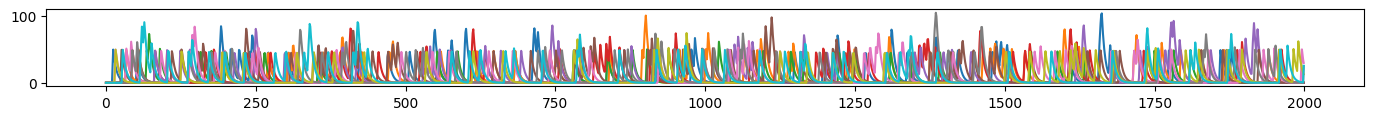

<Axes: >

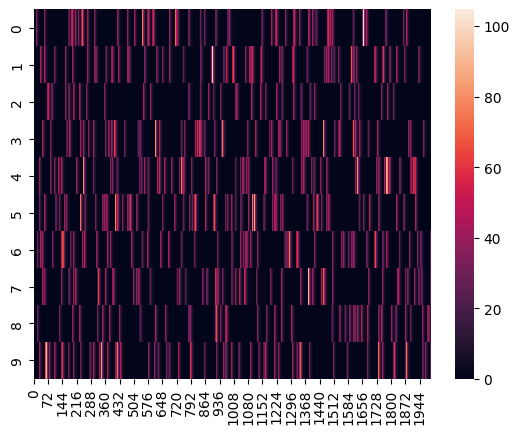

In [3]:
data = f["clean"]

fig = plt.figure(figsize=(17, 1))
for _ in data:
    plt.plot(_)

plt.show()
sns.heatmap(data)

<Axes: >

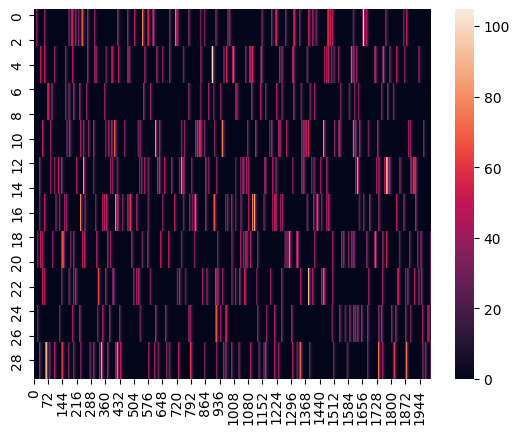

In [4]:
n_pixels = 3

clean = np.zeros((data.shape[0] * n_pixels, data.shape[1]))

for i in range(data.shape[0]):
    clean[i * n_pixels: (i * n_pixels) + n_pixels] = data[i]

sns.heatmap(clean)

100%|█████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 19.38it/s]


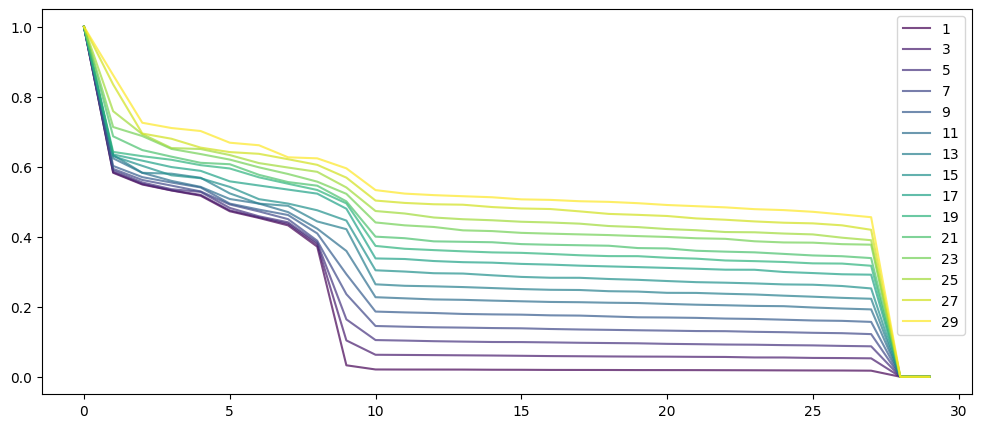

In [5]:
gaussian_noise = f["noise"]["gaussian"]

fig = plt.figure(figsize=(12, 5))

plt.rc('axes', prop_cycle=(cycler('color', plt.cm.viridis(np.linspace(0, 1, len(gaussian_noise.keys()))))))

u_n, s_n, v_n = dict(), dict(), dict()

for n in tqdm(sorted(map(int, gaussian_noise.keys()))):
    Y = clean[:] + gaussian_noise[str(n)][:]
    Y[-3:] = gaussian_noise[str(n)][-1]

    u, s, v = linalg.svd(Y)

    # pca = SparsePCA(n_components=11, alpha=0.03, U_init=u, V_init=v, max_iter=100)

    # u = pca.fit_transform(Y)
    # v = pca.components_

    u_n[n] = u
    s_n[n] = s
    v_n[n] = v

    plt.plot(s / s.max(), alpha=0.7, label=str(n))

plt.legend()

**Note: LASSO regression takes too long here with the large input array Y**

# Example with sigma = 5

In [6]:
noise_ix = 5

# First SVD vector captures "global" changes

In [7]:
sorted(map(int, gaussian_noise.keys()))

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29]

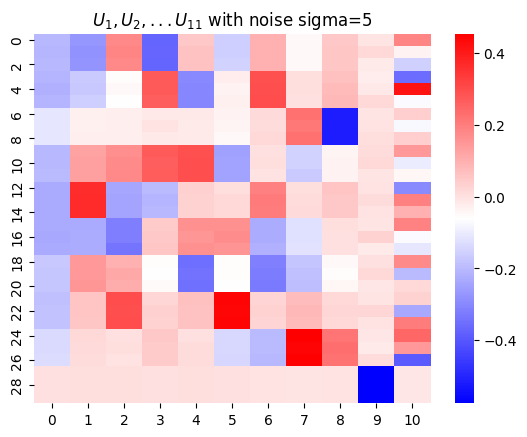

In [8]:
sns.heatmap(u_n[noise_ix][:, :11], cmap="bwr")
plt.title("$U_1, U_2, ... U_{11}$ with noise sigma=5")
plt.show()

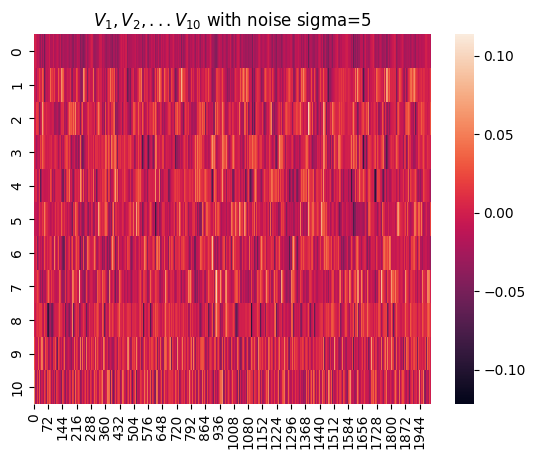

In [9]:
sns.heatmap(v_n[noise_ix][:11])
plt.title("$V_1, V_2, ... V_{10}$ with noise sigma=5")
plt.show()

# Estimate which $V_i$ corresponds to each clean component

<Axes: >

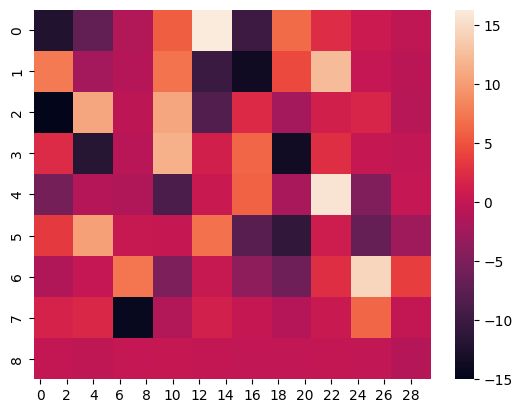

In [10]:
v_cov = (v_n[noise_ix][1:10] @ clean.T) / clean.shape[0]

sns.heatmap(v_cov)

In [11]:
component_ixs = list()

for i in range(0, v_cov.shape[1], n_pixels):
    component_ixs.append(np.abs(v_cov[:, i:i + n_pixels]).sum(axis=1).argmax())

In [12]:
component_ixs

[2, 3, 7, 3, 0, 1, 3, 4, 6, 6]

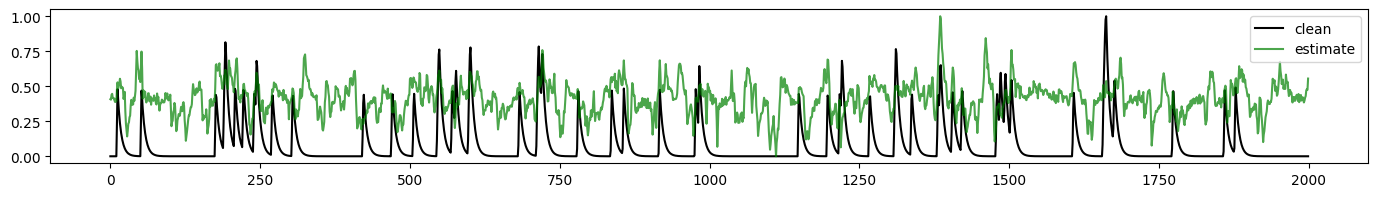

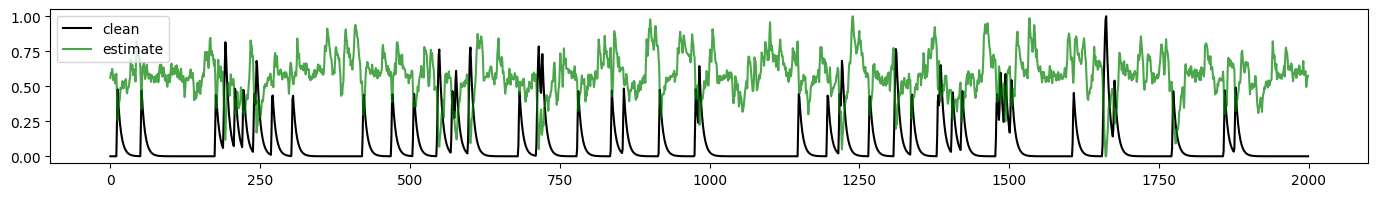

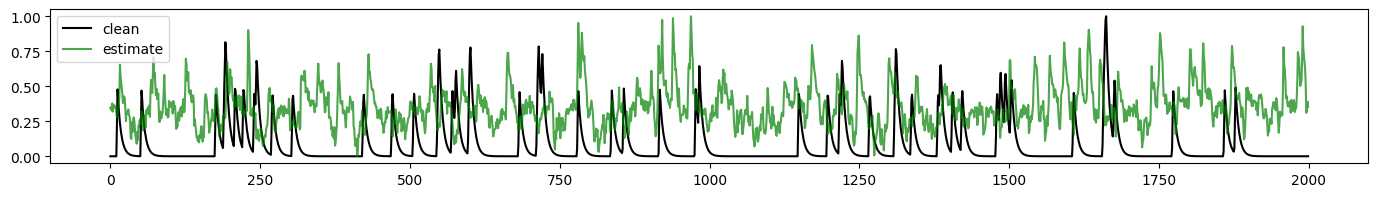

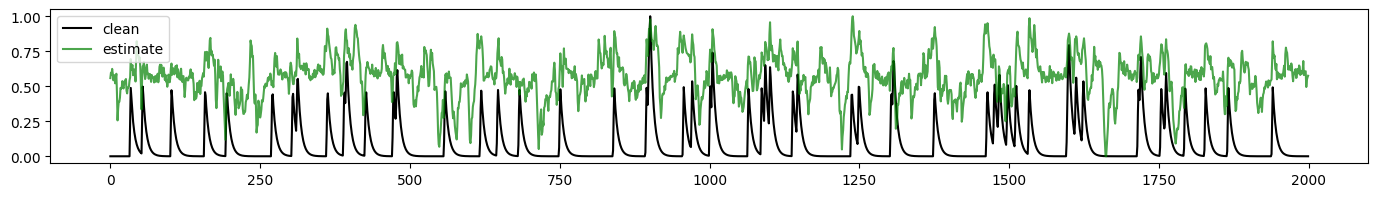

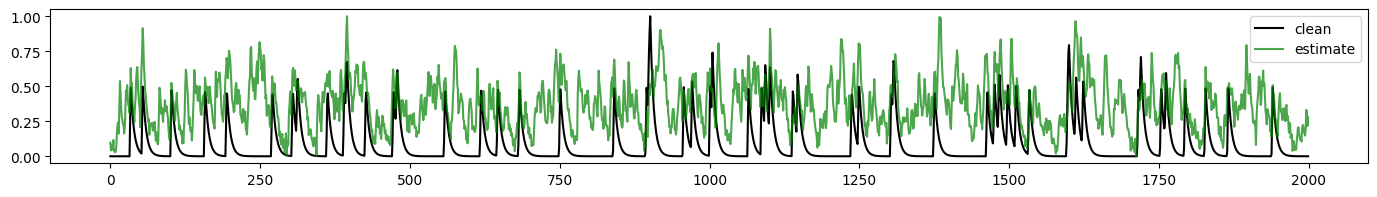

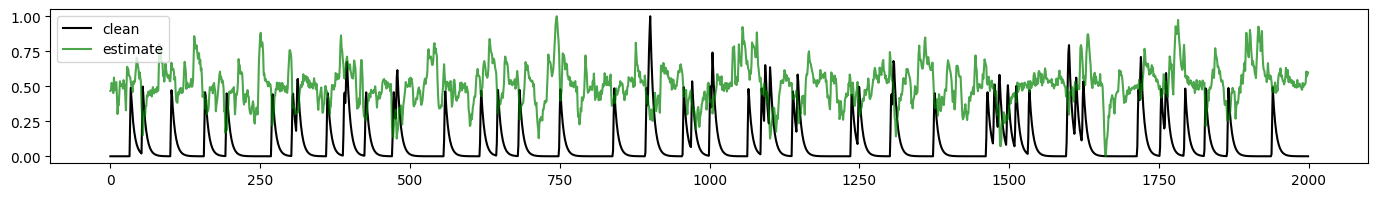

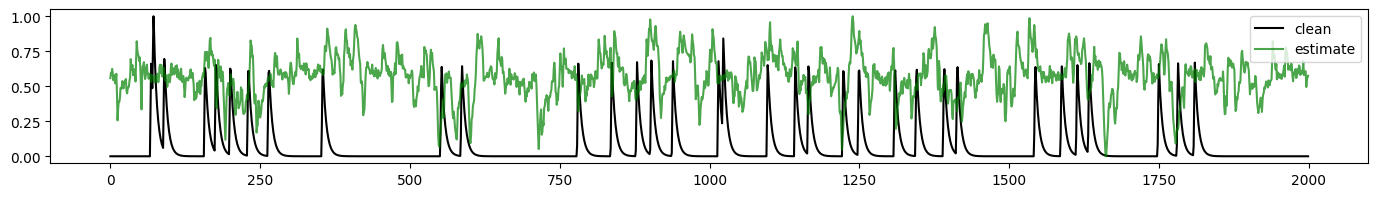

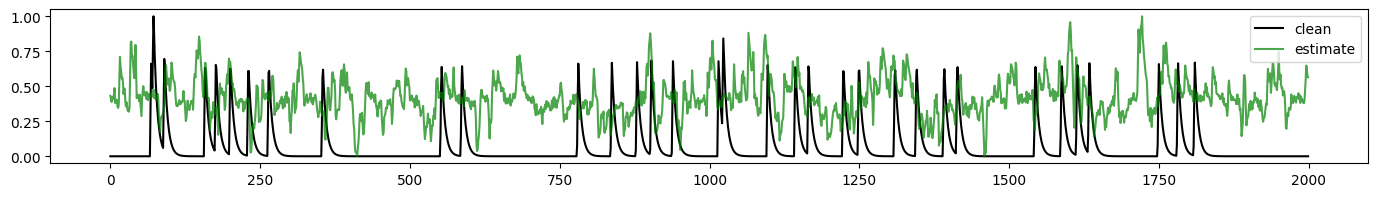

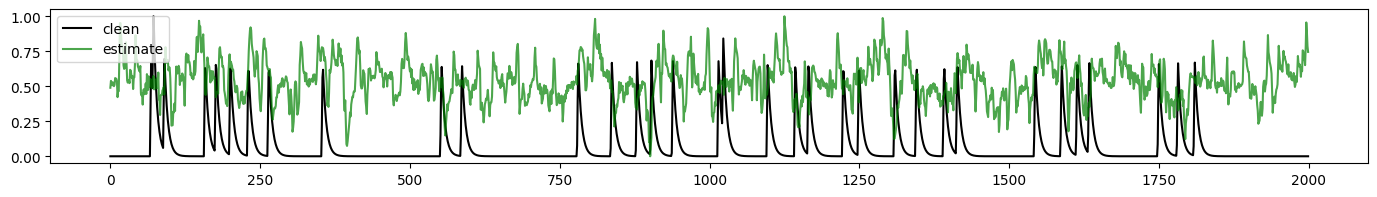

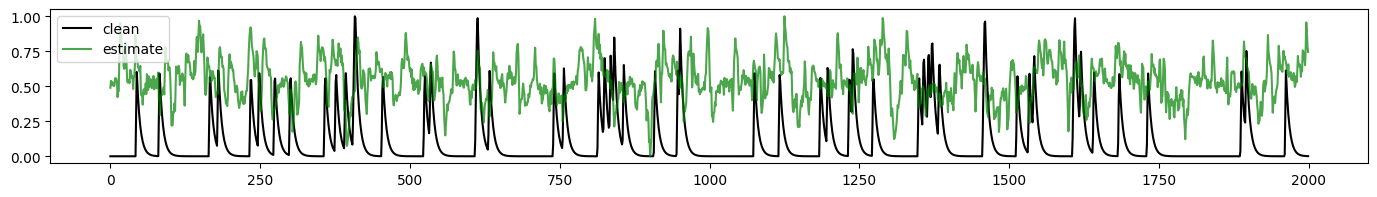

In [13]:
for clean_ix, estimate_ix in enumerate(component_ixs):
    x = clean[clean_ix].copy()
    y = v_n[noise_ix][estimate_ix].copy()

    x -= x.min()
    x /= x.max()

    neg = np.abs(y.min())
    pos = np.abs(y.max())

    y *= np.sign(y.sum())
    
    y -= y.min()
    y /= y.max()
    
    fig = plt.figure(figsize=(17, 2))
    plt.plot(x, color="k", label="clean")
    plt.plot(y, color="green", alpha=0.7, label="estimate")

    plt.legend()
    plt.show()

100%|████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 229.13it/s]


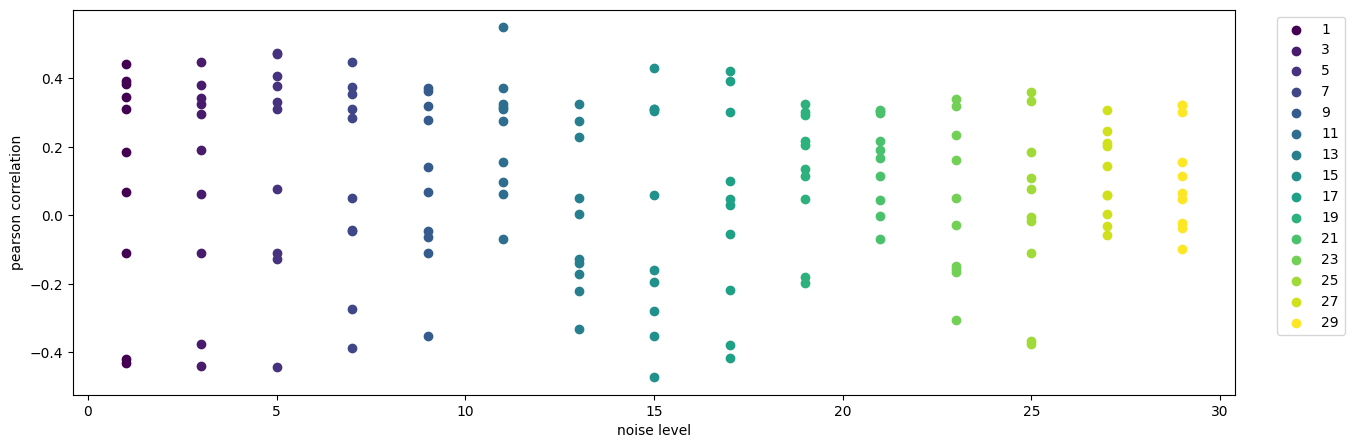

In [14]:
# pearson correlations for each noise level between each component estimate
pc = dict()

fig = plt.figure(figsize=(15, 5))
plt.rc('axes', prop_cycle=(cycler('color', plt.cm.viridis(np.linspace(0, 1, len(gaussian_noise.keys()))))))

for noise_ix in tqdm(sorted(map(int, gaussian_noise.keys()))):
    v_cov = (v_n[noise_ix][1:10] @ clean.T) / clean.shape[0]

    component_ixs = list()

    for i in range(0, v_cov.shape[1], n_pixels):
        component_ixs.append(np.abs(v_cov[:, i:i + n_pixels]).sum(axis=1).argmax())

    _pc = list()
    
    for clean_ix, estimate_ix in enumerate(component_ixs):
        x = data[clean_ix].copy()
        y = v_n[noise_ix][estimate_ix].copy()
    
        x -= x.min()
        x /= x.max()
    
        neg = np.abs(y.min())
        pos = np.abs(y.max())
    
        y *= np.sign(y.sum())
        
        y -= y.min()
        y /= y.max()
        
        _pc.append(np.corrcoef(x, y)[0, 1])
        
    pc[noise_ix] = np.vstack(_pc)

    plt.scatter(x=np.repeat(int(noise_ix), 10), y=pc[noise_ix], label=noise_ix)

plt.xlabel("noise level")
plt.ylabel("pearson correlation")

plt.legend(loc="upper right", bbox_to_anchor=(1.1, 1))
plt.show()

In [ ]:
for